
# **My First Python Data Project: Influencer Marketing**

**Goal:** find out which platforms, influencer categories and campaign types bring the most sales in a Kaggle dataset of 150,000 influencer marketing campaigns

Dataset: [Influencer Marketing ROI Dataset (Kaggle)](https://www.kaggle.com/datasets/tfisthis/influencer-marketing-roi-dataset)

---
# **Part 1. Load the Data**

Import the dataset from Google Drive using Pandas



In [112]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [113]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Project_D/data/influencer_marketing_roi_dataset.csv',
                 parse_dates=["start_date", "end_date"])
print("Rows, columns:", df.shape)

Rows, columns: (150000, 10)


In [114]:
df.head()

,campaign_id,platform,influencer_category,campaign_type,start_date,engagements,estimated_reach,product_sales,campaign_duration_days,end_date
0,CAMP100000,TikTok,Fitness,Giveaway,2022-01-01 00:00:00,79900,1892,2834,14,2022-01-15 00:00:00
1,CAMP100001,YouTube,Food,Product Launch,2022-01-02 00:00:00,47985,437228,165,13,2022-01-15 00:00:00
2,CAMP100002,TikTok,Travel,Brand Awareness,2022-01-03 00:00:00,13875,982513,2539,5,2022-01-08 00:00:00
3,CAMP100003,YouTube,Food,Brand Awareness,2022-01-04 00:00:00,41200,213400,100,20,2022-01-24 00:00:00
4,CAMP100004,Instagram,Food,Giveaway,2022-01-05 00:00:00,96998,42501,550,28,2022-02-02 00:00:00


---
# **Part 2. First look**

In [115]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   campaign_id             150000 non-null  object
 1   platform                150000 non-null  object
 2   influencer_category     150000 non-null  object
 3   campaign_type           150000 non-null  object
 4   start_date              150000 non-null  object
 5   engagements             150000 non-null  int64 
 6   estimated_reach         150000 non-null  int64 
 7   product_sales           150000 non-null  int64 
 8   campaign_duration_days  150000 non-null  int64 
 9   end_date                150000 non-null  object
dtypes: int64(4), object(6)
memory usage: 11.4+ MB


In [116]:
df.describe().round(1)


,engagements,estimated_reach,product_sales,campaign_duration_days
count,150000.0,150000.0,150000.0,150000.0
mean,50065.3,500239.6,2497.7,15.0
std,28847.3,288003.4,1443.2,8.4
min,100.0,1002.0,0.0,1.0
25%,25060.5,251439.5,1248.0,8.0
50%,50100.5,500073.5,2501.0,15.0
75%,75045.2,750016.8,3746.0,22.0
max,99999.0,999992.0,4999.0,29.0


In [117]:
print("Last start date:", df["start_date"].max())

# Convert to real dates; dates pandas cannot store become NaT (empty)
df["start_date"] = pd.to_datetime(df["start_date"], errors="coerce")
df["end_date"] = pd.to_datetime(df["end_date"], errors="coerce")

print("Start dates too far in the future to store:", df["start_date"].isna().sum())


Last start date: 2432-09-07 00:00:00
Start dates too far in the future to store: 62241


> The file has 150,000 campaigns and 10 columns, with no missing values in the original data. But pandas could not read the dates: they go up to the year 2432, and about 62,000 campaigns start after 2262. Real campaign data can't have dates like this



---
# **Part 3. Basic checks**

In [118]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Unique campaign IDs:", df["campaign_id"].is_unique)

Missing values: 124498
Duplicate rows: 0
Unique campaign IDs: True



> No duplicate rows and every campaign ID is unique.
The only missing values are in the date columns. These are the ~62,000 dates after 2262
that pandas could not store (see above). The original file had no missing values



---
# **Part 4. Most used platforms**

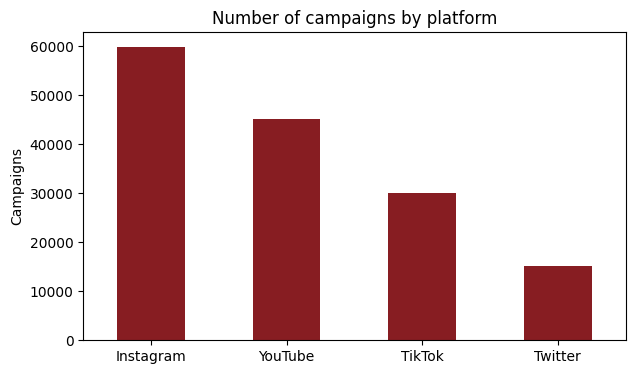

,count
platform,
Instagram,39.9
YouTube,30.1
TikTok,20.0
Twitter,10.0


In [119]:
counts = df["platform"].value_counts()

counts.plot (kind="bar", color= "#871D22", figsize=(7, 4))
plt.title("Number of campaigns by platform")
plt.xlabel("")
plt.ylabel("Campaigns")
plt.xticks(rotation=0)
plt.show()

(counts / counts.sum() * 100).round(1)



> Instagram is the most frequently used platform, accounting for approximately 40% of all campaigns, followed by YouTube (30%), TikTok (20%), and Twitter (10%)

---
# **Part 5. Top selling campaign type, category, and platform**

In [120]:
for column in ["platform", "influencer_category", "campaign_type"]:
    avg_sales = df.groupby(column)["product_sales"].mean().round(0).sort_values(ascending=False)
    print(avg_sales, "\n")

platform
YouTube      2504.0
Twitter      2499.0
Instagram    2495.0
TikTok       2493.0
Name: product_sales, dtype: float64 

influencer_category
Travel     2508.0
Food       2506.0
Fitness    2503.0
Tech       2503.0
Beauty     2492.0
Fashion    2488.0
Gaming     2483.0
Name: product_sales, dtype: float64 

campaign_type
Brand Awareness    2502.0
Seasonal Sale      2499.0
Giveaway           2498.0
Event Promotion    2496.0
Product Launch     2493.0
Name: product_sales, dtype: float64 



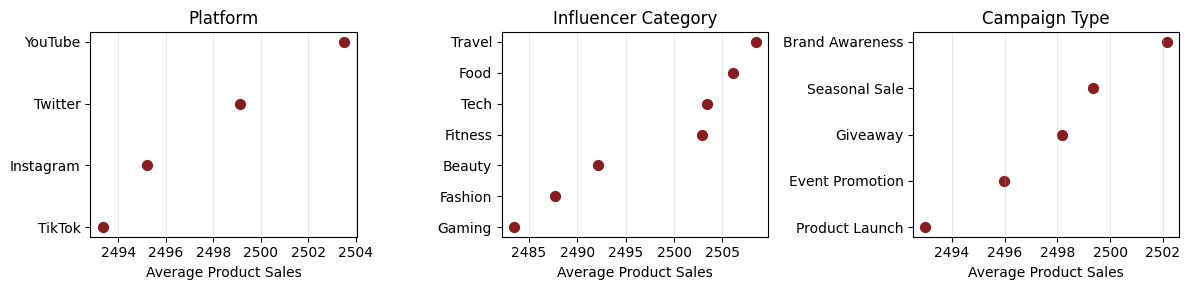

In [121]:
columns = ["platform", "influencer_category", "campaign_type"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, column in zip(axes, columns):
    avg_sales = df.groupby(column)["product_sales"].mean().sort_values()

    ax.scatter(avg_sales.values, avg_sales.index, s=50,  color="#871D22")
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Average Product Sales")
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [122]:
df["engagement_rate_%"] = df["engagements"] / df["estimated_reach"] * 100

df.groupby("platform").agg(
    campaigns=("campaign_id", "count"),
    avg_sales=("product_sales", "mean"),
    avg_engagements=("engagements", "mean"),
    median_engagement_rate=("engagement_rate_%", "median"),
).round(1)

,campaigns,avg_sales,avg_engagements,median_engagement_rate
platform,,,,
Instagram,59819,2495.2,50119.5,10.0
TikTok,29984,2493.3,49824.6,9.9
Twitter,15058,2499.1,50365.0,10.1
YouTube,45139,2503.5,50053.3,10.0


#№ Result:

 Average sales are nearly identical across platforms, categories, and campaign types (around 2,500). Engagement metrics also show very little variation.

 The results raised a question: why are the average sales and engagement metrics so similar across all groups? In the next section, I use Claude as an AI research assistant to explore this question further

---
# **Part 6. Additional Exploration (AI-Assisted)**


## 6.1 Are the dates and values realistic?

In [123]:
print("First campaign starts:", df["start_date"].min().date())
print("Last campaign starts: ", df["start_date"].max().date())

per_day = df.groupby(df["start_date"].dt.date).size()
print("Campaigns per start day (min / max):", per_day.min(), "/", per_day.max())

too_many = df[df["engagements"] > df["estimated_reach"]]
print("Campaigns with engagements > reach:", len(too_many), f"({len(too_many) / len(df):.1%})")
too_many[["platform", "engagements", "estimated_reach"]].head(3)

First campaign starts: 2022-01-01
Last campaign starts:  2262-04-11
Campaigns per start day (min / max): 1 / 1
Campaigns with engagements > reach: 7391 (4.9%)


,platform,engagements,estimated_reach
0,TikTok,79900,1892
4,Instagram,96998,42501
8,Instagram,84035,66087




> Campaign start dates begin in 2022 and, as shown in Part 2, go up to the year 2432 (dates after 2262 could not be stored by pandas, so the maximum shown here is 2262). There is exactly one campaign per day, and ~5% of campaigns have more engagements than people reached





## 6.2 What do the distributions look like?

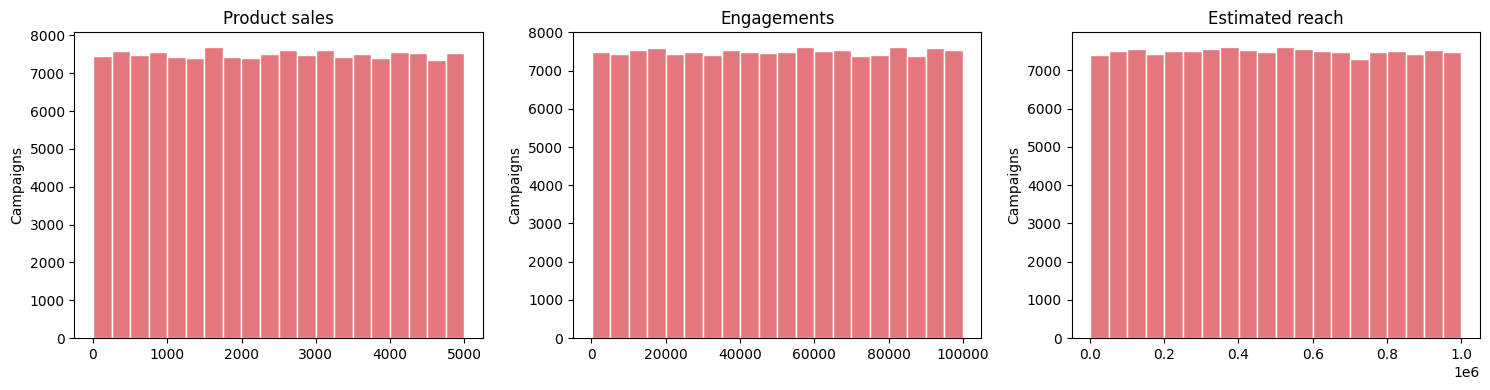

In [124]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["product_sales", "engagements", "estimated_reach"]):
    df[column].plot(kind="hist", bins=20, ax=ax, color="#E2787E", edgecolor="white")
    ax.set_title(column.replace("_", " ").capitalize())
    ax.set_ylabel("Campaigns")
plt.tight_layout()
plt.show()



> All three histograms are flat: every value from minimum to maximum is equally likely. This is typical for data generated with a random number function, not for real sales



## 6.3 Do more engagements lead to more sales?

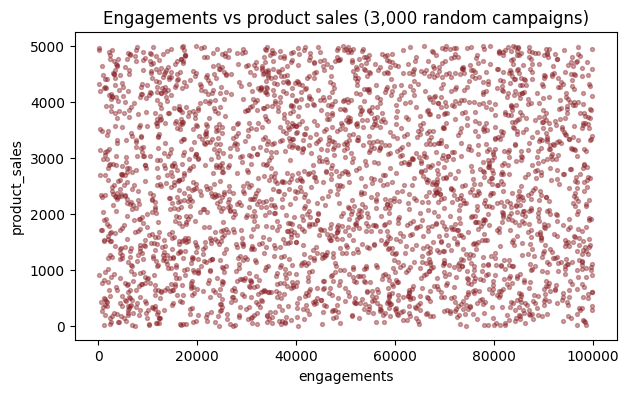

Correlation, full data:   -0.005
Correlation, sample:      0.014


,engagements,estimated_reach,product_sales,campaign_duration_days
engagements,1.0,0.0,0.0,0.0
estimated_reach,0.0,1.0,0.0,0.0
product_sales,0.0,0.0,1.0,0.0
campaign_duration_days,0.0,0.0,0.0,1.0


In [125]:
sample = df.sample(3000, random_state=42)
sample.plot(kind="scatter", x="engagements", y="product_sales", alpha=0.4, s=8, color ="#871D22", figsize=(7, 4))
plt.title("Engagements vs product sales (3,000 random campaigns)")
plt.show()

cols = ["engagements", "estimated_reach", "product_sales", "campaign_duration_days"]
print("Correlation, full data:  ", round(df["engagements"].corr(df["product_sales"]), 3))
print("Correlation, sample:     ", round(sample["engagements"].corr(sample["product_sales"]), 3))
df[cols].corr().round(2) + 0.0

> There is no relationship at all between engagements, reach, duration and sales (all correlations ≈ 0)

## 6.4  Are the small differences between groups real?

In [126]:
from scipy import stats

for column in ["platform", "influencer_category", "campaign_type"]:
    groups = [g["product_sales"] for _, g in df.groupby(column)]
    result = stats.f_oneway(*groups)
    print(f"{column:20}  groups: {len(groups)}  rows: {sum(len(g) for g in groups):,}  "
          f"p-value: {result.pvalue:.2f}")

platform              groups: 4  rows: 150,000  p-value: 0.75
influencer_category   groups: 7  rows: 150,000  p-value: 0.43
campaign_type         groups: 5  rows: 150,000  p-value: 0.95


> The p-value helps determine whether observed differences are statistically significant or could be due to chance. A common rule is: p < 0.05 means the difference is probably real. Here every p-value is far above 0.05, so the differences between platforms, categories and campaign types are just random noise

## 6.5 A reusable data quality check

In [127]:
def quality_report(data):
    """Print simple data quality checks for a DataFrame."""
    print("Rows:", len(data))
    missing = data.isna().sum()
    print("Missing values per column:", missing[missing > 0].to_dict() or "none")
    print("Duplicate rows:", data.duplicated().sum())
    for column in data.select_dtypes("number").columns:
        negatives = (data[column] < 0).sum()
        if negatives:
            print(f"Negative values in {column}: {negatives}")


# My test: a small table with problems I added on purpose
test = pd.DataFrame({"sales": [10, -5, None, 10], "city": ["A", "B", "C", "A"]})
test.loc[3] = test.loc[0]          # duplicate row
quality_report(test)

Rows: 4
Missing values per column: {'sales': 1}
Duplicate rows: 1
Negative values in sales: 1


In [128]:
quality_report(df)


Rows: 150000
Missing values per column: {'start_date': 62241, 'end_date': 62257}
Duplicate rows: 0


---
# **Conclusions**



1.  **Most used platform:** Instagram (~40%), then YouTube, TikTok and Twitter.
2.  **Best performers:** none. Sales, engagements and engagement rate are almost the same across all groups, and the statistical test confirms the small differences are random.
3. **Data quality:** some values are unusual: start dates go up to the year 2432, there is one campaign per day, and some campaigns have more engagements than reach. Sales are spread evenly and show no relationship with engagement. This suggests the data may be simulated, so it is better suited for practice than for real marketing decisions.


**What I Learned:**

During this project, I practiced:

* Loading and exploring a dataset using pandas
* Checking data quality (missing values, duplicates, unusual values)
* Grouping data and calculating summary statistics
* Comparing different campaign groups
* Creating visualizations with Matplotlib
* Using a statistical test to evaluate differences
* Interpreting results and recognizing the limitations of a dataset
* Using an AI assistant (Claude) to explore the data in more depth
* Structuring a notebook with Markdown: headings, lists and short notes after each step


**This project helped me practice working with a public dataset from Kaggle using Python and pandas. It also showed me the importance of looking beyond average values, checking whether differences are statistically significant, and checking data quality before drawing conclusions.**